### <b>10차시 미니 프로젝트 - 질문하고 그래프로 답하기</b>

* 두 CSV로 <b>질문 세 개</b>를 세우고, 질문마다 필요한 열·필터·집계로 <b>그래프에 넣을 표</b>를 먼저 만든다.
* 질문의 종류(비교·관계·분포)에 맞는 그래프를 고르고, 제목에 질문 대신 <b>답</b>을 쓴다. 세 그래프를 <b>1×3 요약 그림</b> 한 장으로 묶어 저장한다.
* <b>점검 목록</b> 다섯 가지로 일부러 덜 다듬은 그래프를 고친다. 그래프는 질문에 답하는 그림이다.

* 맨 위 코드 셀은 <b>준비 셀</b>이다. 구글 드라이브를 연결해 실습 폴더로 이동하고, 한글 폰트를 설치해 등록한다.
  * 구글 드라이브에 <b>데이터_시각화_실습</b> 폴더를 만들고, 그 안에 <b>data</b> 폴더를 올려 둔 뒤 실행한다.
  * 내용은 고치지 않고 실행만 한다. 드라이브 접근을 묻는 창이 뜨면 허용한다. 출력에 CSV 파일 이름 두 개가 보이면 끝난 것이다.
  * 세션이 끊겨도 입력한 코드는 남아 있다. 이어서 할 셀을 선택하고 <b>런타임 › 이전 셀 실행</b>을 누르면 준비 셀부터 다시 실행된다.
* 나머지 코드 칸은 강의를 따라 입력한다. 주석(#)은 입력하지 않아도 되고, 앞 셀과 비슷한 코드는 복사해 고친다.

In [1]:
# keep
# 1. 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 2. 실습 폴더로 기본 작업 위치 이동 (폴더명 변경 필요)
import os
os.chdir('/content/drive/MyDrive/데이터_시각화_실습')

# 3. 현재 위치 확인 (설정한 폴더 경로가 출력됨)
print("현재 작업 폴더:", os.getcwd())

# 4. 나눔고딕 폰트를 설치하고 Matplotlib에 등록
!apt-get -qq install -y fonts-nanum > /dev/null
from matplotlib import font_manager
font_manager.fontManager.addfont('/usr/share/fonts/truetype/nanum/NanumGothic.ttf')

# 5. 실습 데이터 확인 (CSV 파일 이름 두 개가 출력됨)
!ls data

* 준비 셀 다음 셀에 6차시에서 정한 <b>설정 셀</b>을 그대로 입력한다.
  * <b>sns.set_theme(...)</b>에 한글 폰트와 마이너스 설정을 함께 넘긴다. <b>sns.set_theme()</b>을 인자 없이 불러 글자가 깨지면 이 셀을 다시 실행한다. 세션을 다시 시작했다면 준비 셀부터 실행한다.

In [2]:
# 표는 pandas, 그래프는 plt와 Seaborn으로 다룬다
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 테마와 한글 폰트를 함께 정한다
sns.set_theme(style='whitegrid', font='NanumGothic', rc={'axes.unicode_minus': False})

* 오늘은 두 파일을 모두 쓴다. 2차시와 같은 방법으로 읽는다. <b>data</b> 폴더는 드라이브의 실습 폴더에 있다.
  * <b>students</b>: 학생 300명의 생활 습관 설문(가상), 학생 1명 = 1행
  * <b>cafe</b>: 캠퍼스 카페 1년 일별 판매(가상), 하루 = 1행
* 전공 순서 리스트(6차시)도 미리 만들어 둔다.

In [3]:
# 학생 설문 CSV를 읽어 students에 담는다
students = pd.read_csv('data/students.csv')
# 카페 판매 CSV를 date 열은 날짜로 읽어 cafe에 담는다
cafe = pd.read_csv('data/cafe_sales.csv', parse_dates=['date'])
# 두 표의 행과 열 수를 출력한다
print(students.shape, cafe.shape)

# 전공 순서 리스트
major_order = ['공학', '자연과학', '사회과학', '인문', '예체능']

(300, 12) (365, 14)


#### <b>1) 질문 세 개와 그래프 전에 답을 확인할 표 준비</b>

* 그래프를 그리기 전에 질문을 정한다. 좋은 질문은 <b>"무엇을 무엇과 비교하는가"</b>가 분명하다.
* 오늘의 질문 세 개
  * <b>① 시험 주간에 카페 손님은 얼마나 늘까?</b> (비교) - cafe
  * <b>② 공부 시간과 점수의 관계는 전공마다 다를까?</b> (관계) - students
  * <b>③ 주거 형태에 따라 수면 시간이 다를까?</b> (분포) - students
* 질문마다 쓸 열, 고를 행(필터), 묶는 방법(집계)을 정하고 2차시 방법으로 그래프 전에 답을 확인할 표를 만든다.
  * 그래프 재료가 되는 표는 ①의 표뿐이다. ②·③의 표는 답을 숫자로 확인하는 데만 쓰고, 그래프는 원래 표로 그린다.

* <b>질문 ①</b>: 시험 주간과 무엇을 비교할지 먼저 정한다.
  * 시험은 학기 중에만 있다. 방학 날까지 넣으면 "평소"가 방학 때문에 낮아져 차이가 부풀려진다.
  * 휴무일(손님 0명, 2차시)은 문을 닫은 날이라 "평소 손님"이 아니다.
  * 그래서 <b>학기 중(1학기·2학기) 영업일</b>만 고르고, 그 안에서 시험 주간(exam_week 1)과 평소(exam_week 0)를 비교한다.

In [4]:
# 학기 중이고 손님이 있는 날만 고른다
semester_days = cafe[(cafe['period'].isin(['1학기', '2학기'])) & (cafe['customers'] > 0)]
# 고른 날이 며칠인지 출력한다
print(len(semester_days))

# 시험 주간 여부별 날 수와 평균 손님 수를 구한다
semester_days.groupby('exam_week')['customers'].agg(['count', 'mean']).round(2)

218


,count,mean
exam_week,,
0,190,340.24
1,28,455.07


* 학기 중 영업일 218일 가운데 평소 190일은 하루 평균 340.24명, 시험 주간 28일은 455.07명이다.
* 그래프에 넣을 표는 평균 두 개다. <b>customers_by_exam</b>으로 저장하고, 시험 주간 평균을 평소 평균으로 나눠 몇 배인지 구한다.
  * Series에서 <b>[0]</b>·<b>[1]</b>은 순서가 아니라 index 이름(exam_week 값 0·1)으로 값을 꺼낸다.

In [5]:
# 시험 주간 여부별 평균 손님 수를 담는다
customers_by_exam = semester_days.groupby('exam_week')['customers'].mean().round(2)
# 평균 두 개를 출력한다
print(customers_by_exam)
# 시험 주간이 평소의 몇 배인지 출력한다
print(round(customers_by_exam[1] / customers_by_exam[0], 2))

exam_week
0    340.24
1    455.07
Name: customers, dtype: float64
1.34


* 시험 주간 손님은 평소의 <b>1.34배</b>다. 이것이 질문 ①의 답이 된다.

* <b>질문 ②</b>: "관계가 다를까"는 전공마다 상관계수(8차시)를 구해 비교한다.
  * 9차시처럼 전공을 하나씩 돌며 그 전공 학생만 골라 r을 구한다.
  * 결과를 <b>사전(dict)</b>에 담았다가 <b>pd.Series(사전)</b>로 바꾸면, 키는 index·값은 값인 Series가 된다.

In [6]:
# 전공별 상관계수를 담을 빈 사전
corr_by_major = {}
# 전공을 차례로 돈다
for major in major_order:
    # 그 전공 학생만 고른다
    part = students[students['major'] == major]
    # 공부 시간과 점수의 상관계수를 사전에 넣는다
    corr_by_major[major] = round(part['study_hours'].corr(part['exam_score']), 2)

# 사전을 Series로 바꾼다
corr_by_major = pd.Series(corr_by_major)
# 전공별 상관계수를 본다
corr_by_major

공학      0.83
자연과학    0.50
사회과학    0.41
인문      0.49
예체능     0.18
dtype: float64

* 다섯 전공 모두 양수다. 공부 시간이 길수록 점수가 높은 방향은 어느 전공이나 같다.
* 세기는 다르다. <b>공학 0.83</b>이 가장 뚜렷하고 <b>예체능 0.18</b>이 가장 약하다.
  * 자연과학 0.50과 인문 0.49처럼 거의 같은 값은 순위를 매기지 않는다.

* <b>질문 ③</b>: "다를까"를 평균 하나로만 보면 퍼짐을 놓친다(6차시). 주거별로 응답 수·평균·중앙값을 함께 본다.
  * sleep_hours에는 빈 값 15개가 있다(2차시). <b>count</b>는 빈 값을 뺀 응답 수다.

In [7]:
# 주거별 응답 수, 평균, 중앙값을 구한다
sleep_by_housing = students.groupby('housing')['sleep_hours'].agg(['count', 'mean', 'median']).round(2)
# 표를 본다
sleep_by_housing

,count,mean,median
housing,,,
기숙사,83,6.46,6.3
자취,110,6.67,6.8
통학,92,6.48,6.5


* 평균은 6.46~6.67시간, 중앙값은 6.3~6.8시간이다. 가장 큰 차이도 평균 약 0.2시간(약 13분)이다.
* 표만으로는 이 차이가 큰지 작은지 판단하기 어렵다. 2)에서 박스플롯으로 퍼짐까지 보고 답한다.

#### <b>2) 질문별 그래프 세 개 그리기</b>

* 질문의 종류가 그래프의 종류를 정한다.
  * 비교(① 평소 vs 시험 주간) → <b>막대</b>(4차시)
  * 관계(② 공부 시간-점수, 전공별) → <b>회귀선</b>(8차시)
  * 분포(③ 주거별 수면 시간) → <b>박스플롯</b>(6차시)
* 제목에는 질문이 아니라 <b>답</b>을 쓴다(5차시). 보는 사람이 제목만 읽어도 결론을 안다.

* <b>질문 ①</b>: 평균 두 개를 막대 두 개로 그린다.
  * 0과 1 대신 <b>'평소'</b>, <b>'시험 주간'</b> 글자 리스트를 x로 넘긴다. 값 순서(0, 1)와 글자 순서를 같게 둔다.
  * 시험 주간 막대만 강조색, 평소 막대는 회색이다(5차시).
  * 막대는 길이로 비교하므로 y축이 0에서 시작해야 한다. ax.bar는 기본으로 0에서 시작한다.

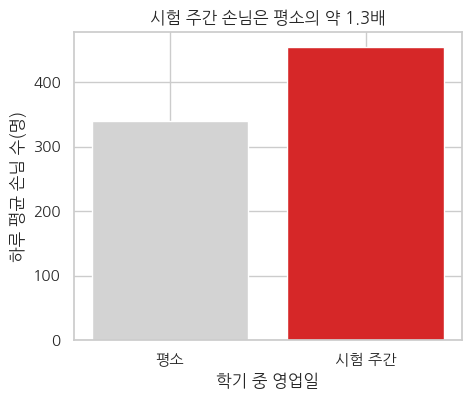

In [8]:
# 그래프를 그릴 칸을 만든다
fig, ax = plt.subplots(figsize=(5, 4))
# 평소는 회색, 시험 주간은 빨강 막대로 그린다
ax.bar(['평소', '시험 주간'], customers_by_exam.values, color=['lightgray', '#d62728'])
# 제목과 축 이름을 단다
ax.set_title('시험 주간 손님은 평소의 약 1.3배')
ax.set_xlabel('학기 중 영업일')
ax.set_ylabel('하루 평균 손님 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 회색 막대 약 340명, 빨간 막대 약 455명. 빨간 막대가 회색 막대보다 3분의 1쯤 더 길다.

* <b>질문 ②</b>: 8차시 lmplot은 전공마다 칸을 따로 만들었다. 이번에는 다섯 전공의 회귀선을 <b>한 칸에 겹쳐</b> 기울기를 바로 비교한다.
  * regplot은 axes 수준 함수라 같은 ax에 여러 번 그릴 수 있다(8차시).
  * <b>scatter=False</b>: 점은 빼고 회귀선만 긋는다. 점 300개가 겹치면 선이 가려진다.
  * <b>ci=None</b>: 신뢰구간 띠를 그리지 않는다. 띠 다섯 개가 겹치면 읽기 어렵다.
  * <b>label=major</b>: 범례 이름. 색은 부를 때마다 다음 기본 색이 된다.

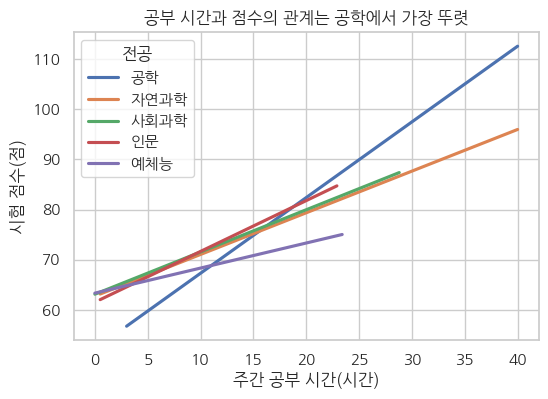

In [9]:
# 그래프를 그릴 칸을 만든다
fig, ax = plt.subplots(figsize=(6, 4))
# 전공을 차례로 돈다
for major in major_order:
    # 그 전공 학생만 고른다
    part = students[students['major'] == major]
    # 점과 띠 없이 회귀선만 긋는다
    sns.regplot(data=part, x='study_hours', y='exam_score', scatter=False, ci=None, label=major, ax=ax)
# 제목과 축 이름을 단다
ax.set_title('공부 시간과 점수의 관계는 공학에서 가장 뚜렷')
ax.set_xlabel('주간 공부 시간(시간)')
ax.set_ylabel('시험 점수(점)')
# 범례를 단다
ax.legend(title='전공')
# 그래프를 화면에 보여 준다
plt.show()

* 다섯 선이 모두 오른쪽 위로 오른다. 방향은 같다.
* 공학 선이 가장 가파르고, 예체능 선이 가장 완만하다. 1)의 r(공학 0.83, 예체능 0.18)과 양 끝(공학·예체능)은 같은 방향이다. 기울기와 r은 다른 숫자다.
* 공학 선 오른쪽 끝이 100점을 넘는다. 점수가 100점을 넘었다는 뜻이 아니라, 직선을 그 전공의 가장 긴 공부 시간까지 그었기 때문이다.
* 회귀선은 관계의 방향을 보여 줄 뿐 원인을 말하지 않는다(8차시). "공학은 공부하면 점수가 더 오른다"가 아니라 "공학 학생들에게서 공부 시간과 점수가 더 뚜렷하게 함께 움직인다"로 읽는다.

* <b>질문 ③</b>: 주거별 수면 시간 분포를 박스플롯으로 그린다(6차시).
  * 차이가 없을 수도 있는 질문이라 강조할 상자가 없다. <b>color='lightgray'</b>로 세 상자를 같은 색으로 둔다.
  * 빈 값은 Seaborn이 알아서 뺀다(6차시).

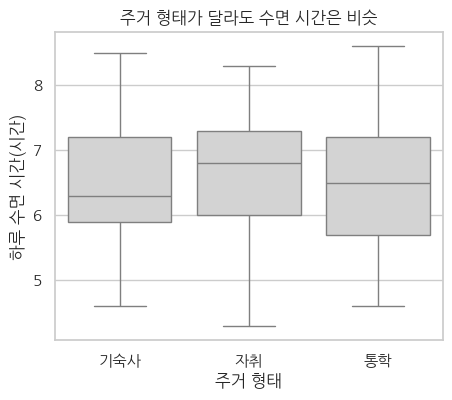

In [10]:
# 그래프를 그릴 칸을 만든다
fig, ax = plt.subplots(figsize=(5, 4))
# 주거별 수면 시간을 같은 색 상자로 그린다
sns.boxplot(data=students, x='housing', y='sleep_hours', color='lightgray', ax=ax)
# 제목과 축 이름을 단다
ax.set_title('주거 형태가 달라도 수면 시간은 비슷')
ax.set_xlabel('주거 형태')
ax.set_ylabel('하루 수면 시간(시간)')
# 그래프를 화면에 보여 준다
plt.show()

* 세 상자의 높이(가운데 50%)가 대부분 겹친다. 상자 아래·위 끝이 기숙사 5.9~7.2, 자취 6.0~7.3, 통학 5.7~7.2시간이다.
* 상자 안 가로선(중앙값)은 자취가 조금 높지만(6.8시간), 상자끼리 겹치는 부분이 훨씬 크다. 답은 "주거 형태에 따라 수면 시간이 크게 다르지 않다"이다.
* 차이가 없다는 것도 답이다(9차시). 질문을 정하고 확인했기 때문에 "다르지 않다"고 말할 수 있다.

#### <b>3) 1×3 요약 그림으로 묶어 저장</b>

* 질문 하나에 그래프 하나. 세 그래프를 5차시의 <b>plt.subplots(1, 3)</b>으로 한 장에 모은다.
  * 한 줄 배치라 칸은 <b>axes[0]</b>·<b>axes[1]</b>·<b>axes[2]</b>로 고른다(5차시).
  * Matplotlib 함수는 <b>axes[i].bar(...)</b>처럼, Seaborn 함수는 <b>ax=axes[i]</b>로 칸을 정한다(6차시). 한 그림 안에 섞어 그려도 된다.
* 요약 그림에서는 질문 ②도 강조 규칙을 따른다. 공학 선만 강조색, 나머지 네 전공은 회색이다.
  * 범례에는 공학만 남긴다. <b>label=None</b>인 선은 범례에 들어가지 않는다.
* 그림 전체 제목은 <b>fig.suptitle</b>, 저장은 <b>fig.savefig</b>를 <b>plt.show() 앞</b>에 둔다(5차시). 저장 폴더 <b>output</b>을 먼저 만든다.

In [11]:
# 폴더를 다루는 os 모듈을 불러온다
import os

# 그림을 저장할 output 폴더를 만든다
os.makedirs('output', exist_ok=True)

* 2)의 세 셀을 복사해 ax를 axes[i]로 바꾼다.
* 강조할 전공을 마지막에 그려 위에 오게 한다.
  * <b>major_order[::-1]</b>: 리스트를 거꾸로 뒤집는다. 공학이 마지막 차례가 된다.

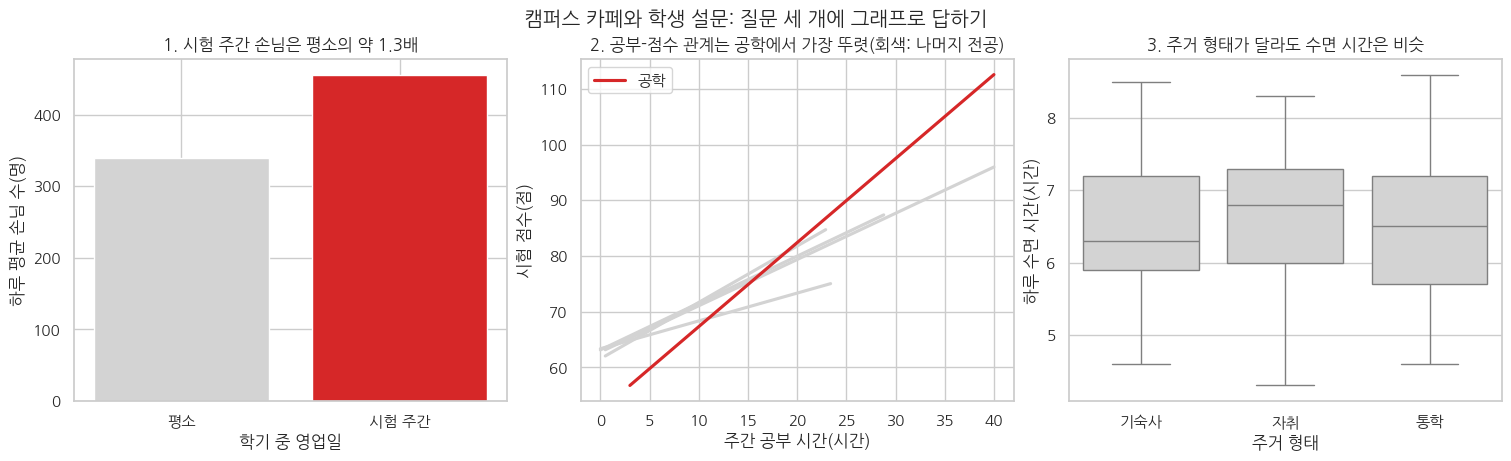

In [12]:
# 한 줄에 세 칸을 만든다
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout='constrained')

# 첫째 칸에 질문 1의 막대를 그린다
axes[0].bar(['평소', '시험 주간'], customers_by_exam.values, color=['lightgray', '#d62728'])
# 첫째 칸의 제목과 축 이름을 단다
axes[0].set_title('1. 시험 주간 손님은 평소의 약 1.3배')
axes[0].set_xlabel('학기 중 영업일')
axes[0].set_ylabel('하루 평균 손님 수(명)')

# 둘째 칸에 전공별 회귀선을 공학이 맨 위에 오도록 거꾸로 긋는다
for major in major_order[::-1]:
    # 그 전공 학생만 고른다
    part = students[students['major'] == major]
    # 공학은 빨강, 나머지는 회색으로 정한다
    color = '#d62728' if major == '공학' else 'lightgray'
    # 공학에만 범례 이름을 준다
    label = '공학' if major == '공학' else None
    # 정한 색과 범례 이름으로 회귀선을 긋는다
    sns.regplot(data=part, x='study_hours', y='exam_score', scatter=False, ci=None,
                color=color, label=label, ax=axes[1])
# 둘째 칸의 제목과 축 이름을 단다
axes[1].set_title('2. 공부-점수 관계는 공학에서 가장 뚜렷(회색: 나머지 전공)')
axes[1].set_xlabel('주간 공부 시간(시간)')
axes[1].set_ylabel('시험 점수(점)')
# 둘째 칸에 범례를 단다
axes[1].legend()

# 셋째 칸에 주거별 수면 시간 상자를 그린다
sns.boxplot(data=students, x='housing', y='sleep_hours', color='lightgray', ax=axes[2])
# 셋째 칸의 제목과 축 이름을 단다
axes[2].set_title('3. 주거 형태가 달라도 수면 시간은 비슷')
axes[2].set_xlabel('주거 형태')
axes[2].set_ylabel('하루 수면 시간(시간)')

# 그림 전체 제목을 단다
fig.suptitle('캠퍼스 카페와 학생 설문: 질문 세 개에 그래프로 답하기')
# 그림을 파일로 저장한다
fig.savefig('output/summary.png', dpi=200, bbox_inches='tight')
# 그래프를 화면에 보여 준다
plt.show()

* 칸마다 제목이 그 질문의 답이다. 그림 한 장만 보고도 세 가지 결론을 읽을 수 있다.
* 저장된 파일을 확인한다(5차시). 파일은 드라이브의 실습 폴더 안 <b>output</b> 폴더에 생긴다. 드라이브에 저장되므로 세션이 끝나도 남는다.

In [13]:
# output 폴더 안의 파일 목록을 출력한다
print(os.listdir('output'))
# 저장한 그림을 읽어 크기를 출력한다
print(plt.imread('output/summary.png').shape)

['summary.png']
(923, 3023, 4)


* summary.png가 보이고, 크기는 세로 약 900 × 가로 약 3,000 픽셀이다(15×4.5인치 × dpi 200, 여백을 잘라 내 조금 다름).

#### <b>4) 점검 목록으로 그래프 고치기</b>

* 그래프를 다 그렸으면 저장하거나 보여 주기 전에 다섯 가지를 점검한다(이 강의에서 정리한 목록).
  * <b>제목 = 결론</b>: 제목만 읽어도 답을 아는가
  * <b>축 이름과 단위</b>: 축마다 무엇을 어떤 단위로 쟀는지 적었는가
  * <b>막대는 0부터</b>: 막대 그래프의 y축이 0에서 시작하는가(점·선은 아니어도 된다, 7차시)
  * <b>색에 뜻이 있고 범례가 있다</b>: 색마다 뜻이 있고, 그 뜻을 범례·제목·눈금 글자에서 알 수 있는가
  * <b>한글·마이너스가 정상이다</b>: 글자가 네모(□)로 나오거나 음수 부호가 깨지지 않는가
* 아래는 질문 ①을 <b>일부러 덜 다듬어</b> 그린 그래프다. 다섯 가지로 점검해 본다.

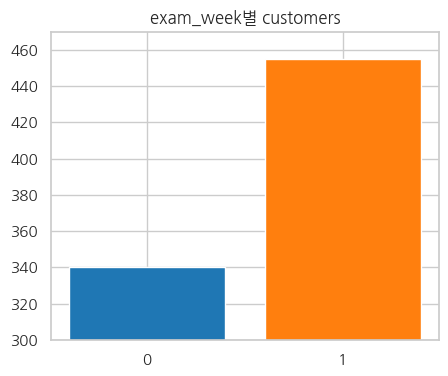

In [14]:
# 그래프를 그릴 칸을 만든다
fig, ax = plt.subplots(figsize=(5, 4))
# 0과 1을 이름으로 막대를 그린다
ax.bar(['0', '1'], customers_by_exam.values, color=['tab:blue', 'tab:orange'])
# y축 범위를 300~470으로 정한다
ax.set_ylim(300, 470)
# 제목을 단다
ax.set_title('exam_week별 customers')
# 그래프를 화면에 보여 준다
plt.show()

* 영상을 멈추고 점검 결과를 먼저 적어 본다.
* 점검 결과
  * <b>제목 = 결론</b>: 실패. 'exam_week별 customers'는 무엇을 그렸는지만 말한다.
  * <b>축 이름과 단위</b>: 실패. x축 0·1이 무슨 뜻인지, y축이 무엇을 몇 명 단위로 쟀는지 없다.
  * <b>막대는 0부터</b>: 실패. y축이 300에서 시작한다. 막대 길이가 약 40 대 155가 되어 시험 주간이 <b>약 4배</b>처럼 보인다. 실제는 1.34배다.
  * <b>색에 뜻이 있고 범례가 있다</b>: 실패. 파랑·주황에 뜻이 없고 범례도 없다.
  * <b>한글·마이너스가 정상이다</b>: 통과. 설정 셀 덕분이다. 제목의 글자가 네모로 나오면 설정 셀을 다시 실행한다. 세션을 다시 시작했다면 준비 셀부터 실행한다.
* 고치는 방법은 2)에서 이미 썼다. 같은 데이터로 고치기 전·후를 나란히 놓아 비교한다.

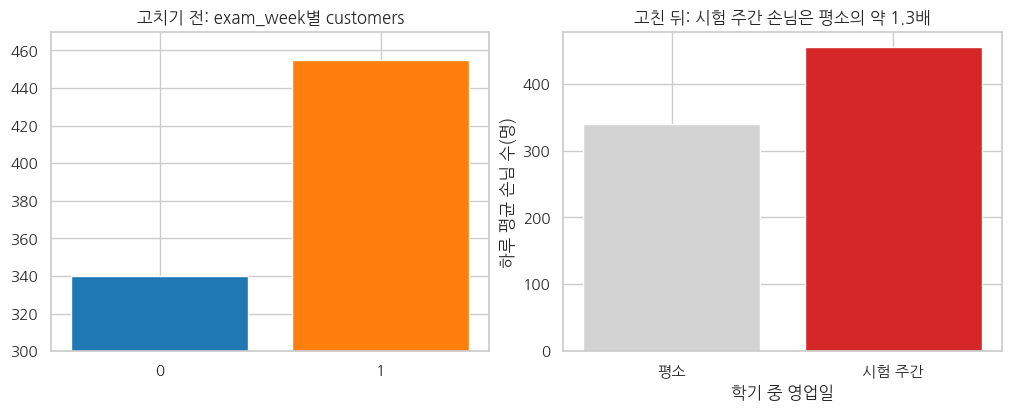

In [15]:
# 1×2 칸을 만든다
fig, axes = plt.subplots(1, 2, figsize=(10, 4), layout='constrained')

# 왼쪽 칸에 고치기 전 막대를 그린다
axes[0].bar(['0', '1'], customers_by_exam.values, color=['tab:blue', 'tab:orange'])
# 왼쪽 칸의 y축 범위를 300~470으로 정한다
axes[0].set_ylim(300, 470)
# 왼쪽 칸 제목을 단다
axes[0].set_title('고치기 전: exam_week별 customers')

# 오른쪽 칸에 고친 뒤 막대를 그린다
axes[1].bar(['평소', '시험 주간'], customers_by_exam.values, color=['lightgray', '#d62728'])
# 오른쪽 칸의 제목과 축 이름을 단다
axes[1].set_title('고친 뒤: 시험 주간 손님은 평소의 약 1.3배')
axes[1].set_xlabel('학기 중 영업일')
axes[1].set_ylabel('하루 평균 손님 수(명)')
# 그래프를 화면에 보여 준다
plt.show()

* 같은 숫자인데 왼쪽은 차이가 크게 부풀려 보이고, 오른쪽은 실제 비율(약 1.3배)대로 보인다.
* 오른쪽은 다섯 가지를 모두 통과한다. 제목이 결론을 말하고, 축이 단위를 말하고, 막대가 0에서 시작하고, 빨강 하나가 시험 주간을 가리킨다.
* 오늘 정리: 질문을 정하고 → 질문에 맞는 표를 만들고 → 질문의 종류에 맞는 그래프를 고르고 → 제목에 답을 쓰고 → 점검 목록으로 다듬어 저장한다. 그래프는 질문에 답하는 그림이다.